# E-Waste Recycling Analysis

Data cleaning and visual analysis of an e-waste recycling dataset. Place `GBA_waste.csv` in the same folder before running.

## 1. Load the data

In [1]:
import pandas as pd

df = pd.read_csv("GBA_waste.csv")
print(df.head())

rows, cols = df.shape

print(f"Rows: {rows}")
print(f"Columns: {cols}")

   ID   Item_Name    Brand   Category  Year_of_Purchase          Condition  \
0   1  Smartphone       HP     Laptop            2015.0             Broken   
1   2  Smartphone       LG     Mobile            2021.0            Working   
2   3      Laptop  Samsung  Appliance            2016.0  Partially Working   
3   4  Smartphone    Apple         TV            2017.0             Broken   
4   5          TV  Samsung  Appliance            2018.0             Broken   

   Quantity  Weight_kg Recycle_Method  Location Recycling_Facility  \
0         1      11.37           Both    Mumbai         Facility C   
1         3       6.29           Both    Mumbai         Facility A   
2         5      13.89           Both    Berlin         Facility B   
3         1       9.47      Automated    Mumbai         Facility B   
4         1      18.70         Manual  Shanghai         Facility A   

                 End_Use  Recycled_Price_USD Toxic_Components  \
0       E-Waste Disposal               17.92 

## 2. Check missing values

In [2]:
missing_summary = df.isnull().sum()
 
print(missing_summary[missing_summary > 0])

Year_of_Purchase        2
Recycle_Method        158
Recycled_Price_USD    140
Toxic_Components      370
dtype: int64


## 3. Treat missing values

In [3]:
df["Year_of_Purchase"] = df["Year_of_Purchase"].fillna(df["Year_of_Purchase"].median())

df["Recycled_Price_USD"] = df["Recycled_Price_USD"].fillna(df["Recycled_Price_USD"].median())

df["Recycle_Method"] = df["Recycle_Method"].fillna(df["Recycle_Method"].mode()[0])

df["Toxic_Components"] = df["Toxic_Components"].fillna("Unknown")

df.isnull().sum()

ID                    0
Item_Name             0
Brand                 0
Category              0
Year_of_Purchase      0
Condition             0
Quantity              0
Weight_kg             0
Recycle_Method        0
Location              0
Recycling_Facility    0
End_Use               0
Recycled_Price_USD    0
Toxic_Components      0
E-Waste_Collector     0
Exported_To           0
dtype: int64

## 4. Average recycled price by category and condition

Table 1: Average Recycled Price (USD) by Category and Condition
Condition  Broken  Partially Working  Working
Category                                     
Appliance   96.41              93.27   107.41
Laptop     113.32             110.59   105.54
Mobile      99.42             104.21   104.25
TV         104.22             100.87    98.77


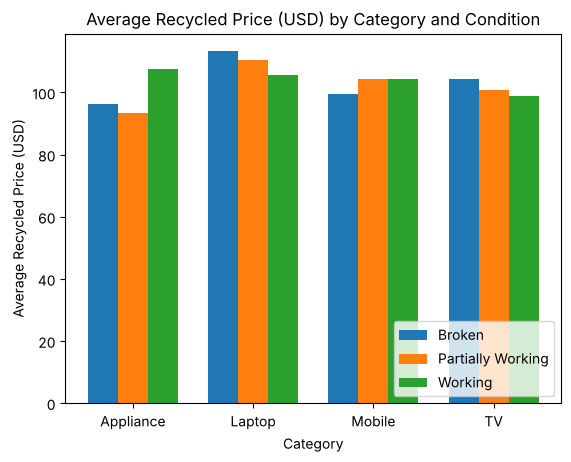

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
 
# Table 1: Average Recycled Price by Category and Condition
table1 = df.groupby(["Category", "Condition"])["Recycled_Price_USD"].mean().round(2).unstack()
print("Table 1: Average Recycled Price (USD) by Category and Condition")
print(table1.to_string())
 
# Bar Chart
categories = table1.index
x = [0, 1, 2, 3]
width = 0.25
 
plt.bar([i - width for i in x], table1["Broken"], width=width, label="Broken")
plt.bar(x, table1["Partially Working"], width=width, label="Partially Working")
plt.bar([i + width for i in x], table1["Working"], width=width, label="Working")
 
plt.xlabel("Category")
plt.ylabel("Average Recycled Price (USD)")
plt.title("Average Recycled Price (USD) by Category and Condition")
plt.xticks(x, categories, rotation=0)
plt.legend(loc="lower right")
plt.show()

## 5. Recycling method by category

Table 2: Count of Recycle Method by Category
Recycle_Method  Automated  Both  Manual
Category                               
Appliance              97   117     175
Laptop                101   106     148
Mobile                138   126     138
TV                    119   100     164


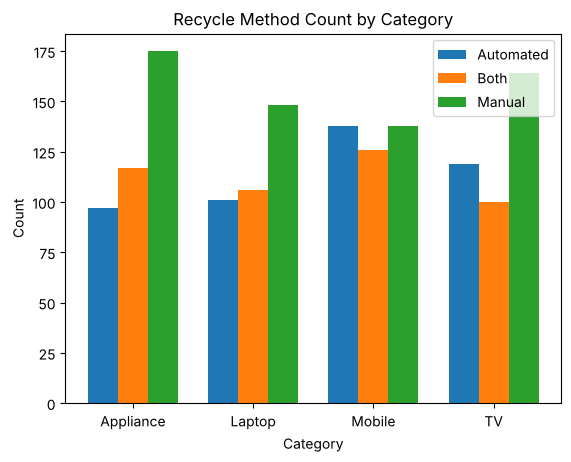

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
 
# Table 2: Count of Recycle Method by Category
table2 = df.groupby(["Category", "Recycle_Method"]).size().unstack(fill_value=0)
print("Table 2: Count of Recycle Method by Category")
print(table2.to_string())
 
# Bar Chart
plt.bar([0, 1, 2, 3], table2["Automated"], width=0.25, label="Automated")
plt.bar([0.25, 1.25, 2.25, 3.25], table2["Both"], width=0.25, label="Both")
plt.bar([0.5, 1.5, 2.5, 3.5], table2["Manual"], width=0.25, label="Manual")
 
plt.xlabel("Category")
plt.ylabel("Count")
plt.title("Recycle Method Count by Category")
plt.xticks([0.25, 1.25, 2.25, 3.25], table2.index, rotation=0)
plt.legend(loc="upper right")
plt.show()

## 6. Average recycled price by year of purchase

Table 3: Average Recycled Price (USD) by Year of Purchase
Year_of_Purchase
2010    108.17
2011     98.91
2012     98.43
2013    105.21
2014    106.86
2015    105.45
2016     95.75
2017    114.91
2018    102.92
2019    103.34
2020    101.61
2021    104.31
2022     95.30
2023    101.36


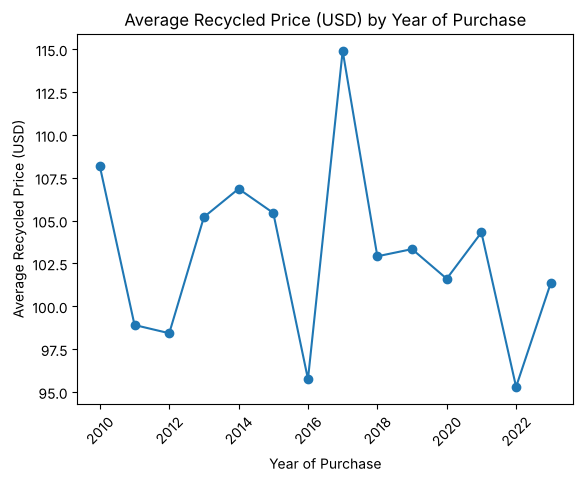

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
 
# Table 3: Average Recycled Price by Year of Purchase
table3 = df.groupby("Year_of_Purchase")["Recycled_Price_USD"].mean().round(2)
table3.index = table3.index.astype(int)
print("Table 3: Average Recycled Price (USD) by Year of Purchase")
print(table3.to_string())
 
# Line Chart
plt.plot(table3.index, table3.values, marker="o")
plt.xlabel("Year of Purchase")
plt.ylabel("Average Recycled Price (USD)")
plt.title("Average Recycled Price (USD) by Year of Purchase")
plt.xticks(rotation=45)
plt.show()